In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis, jarque_bera

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

from xgboost import XGBRegressor

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("gold_2007_to_present.csv")
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"])

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.ffill().bfill()
df = df.set_index("Date")

print(df.head())

                 Close        High         Low        Open  Volume
Date                                                              
2007-01-02  635.200012  635.200012  635.200012  635.200012      17
2007-01-03  627.099976  640.400024  628.500000  640.400024      38
2007-01-04  623.900024  624.500000  624.500000  624.500000       4
2007-01-05  604.900024  623.700012  617.299988  623.700012     531
2007-01-08  607.500000  607.500000  607.500000  607.500000    1000


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\486738972.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [3]:
df1 = df.loc[: "2010-12-31"]
df2 = df.loc["2011-01-01":"2019-12-31"]
df3 = df.loc["2020-01-01":"2021-12-31"]
df4 = df.loc["2022-01-01":]

datasets = [df1, df2, df3, df4]
names = ["Pre-2011", "2011–2019", "COVID", "2022+"]

In [4]:
def plot_price_trends(df, name):
    plt.figure(figsize=(14,5))
    for col in ["Open","High","Low","Close"]:
        plt.plot(df.index, df[col], label=col)
    plt.title(f"OHLC Trends – {name}")
    plt.legend()
    plt.show()


def plot_distribution(df, name):
    returns = df["Close"].pct_change().dropna()
    fig, ax = plt.subplots(1,2, figsize=(14,4))
    sns.histplot(df["Close"], kde=True, ax=ax[0])
    sns.histplot(returns, kde=True, ax=ax[1])
    ax[0].set_title("Price Distribution")
    ax[1].set_title("Return Distribution")
    plt.suptitle(name)
    plt.show()


def plot_rolling_stats(df, name):
    returns = df["Close"].pct_change()
    fig, ax = plt.subplots(2,1, figsize=(14,6), sharex=True)
    ax[0].plot(df["Close"])
    ax[0].plot(df["Close"].rolling(30).mean())
    ax[0].set_title("Rolling Mean")
    ax[1].plot(returns.rolling(30).std(), color="red")
    ax[1].set_title("Rolling Volatility")
    plt.suptitle(name)
    plt.show()


def plot_corr_heatmap(df, name):
    plt.figure(figsize=(6,5))
    sns.heatmap(df[["Open","High","Low","Close","Volume"]].corr(),
                annot=True, cmap="coolwarm")
    plt.title(f"Correlation – {name}")
    plt.show()


In [5]:
def analyze_timeseries(df, name):
    s = df["Close"].dropna()
    print(f"\n===== STATISTICAL ANALYSIS: {name} =====")
    print("Mean:", s.mean())
    print("Std:", s.std())
    print("Skew:", skew(s))
    print("Kurtosis:", kurtosis(s))
    print("ADF p:", adfuller(s)[1])

    try:
        print("KPSS p:", kpss(s, regression="c")[1])
    except:
        pass

    plot_acf(s, lags=40)
    plot_pacf(s, lags=40)
    plt.show()

In [6]:
def create_seq(X, y, seq_len=25, flatten=False):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        seq = X[i-seq_len:i]
        Xs.append(seq.flatten() if flatten else seq)
        ys.append(y[i])
    return np.array(Xs), np.array(ys)


def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{label} | MAE:{mae:.3f} RMSE:{rmse:.3f} R2:{r2:.3f}")
    return mae, rmse, r2


In [7]:
def build_convlstm(seq_len, features):
    model = Sequential([
        Conv1D(64,3,activation="relu",padding="same",
               input_shape=(seq_len,features)),
        Dropout(0.2),
        Conv1D(32,3,activation="relu",padding="same"),
        Dropout(0.2),
        LSTM(64),
        Dense(32,activation="relu"),
        Dense(2)
    ])
    model.compile("adam","mse")
    return model



In [8]:
def run_convlstm(df, name):
    X = df[["Open","High","Low","Close"]].values
    y = df[["High","Low"]].values

    sx, sy = StandardScaler(), StandardScaler()
    Xs, ys = sx.fit_transform(X), sy.fit_transform(y)

    Xseq, yseq = create_seq(Xs, ys)
    split = int(len(Xseq)*0.85)

    model = build_convlstm(25, X.shape[1])
    model.fit(Xseq[:split], yseq[:split],
              epochs=40, batch_size=16,
              validation_data=(Xseq[split:], yseq[split:]),
              callbacks=[EarlyStopping(patience=6)],
              verbose=0)

    pred = sy.inverse_transform(model.predict(Xseq[split:]))
    true = sy.inverse_transform(yseq[split:])

    return (
        metrics(true[:,0], pred[:,0], f"ConvLSTM {name} High"),
        metrics(true[:,1], pred[:,1], f"ConvLSTM {name} Low")
    )

In [9]:
def run_xgboost(df, name):
    X = df[["Open","High","Low","Close"]].values
    y = df[["High","Low"]].values

    sx, sy = StandardScaler(), StandardScaler()
    Xs, ys = sx.fit_transform(X), sy.fit_transform(y)

    Xseq, yseq = create_seq(Xs, ys, flatten=True)
    split = int(len(Xseq)*0.85)

    model = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=500, max_depth=8,
            learning_rate=0.05, subsample=0.9,
            colsample_bytree=0.9, objective="reg:squarederror"
        )
    )

    model.fit(Xseq[:split], yseq[:split])
    pred = sy.inverse_transform(model.predict(Xseq[split:]))
    true = sy.inverse_transform(yseq[split:])

    return (
        metrics(true[:,0], pred[:,0], f"XGBoost {name} High"),
        metrics(true[:,1], pred[:,1], f"XGBoost {name} Low")
    )




================ Pre-2011 =================


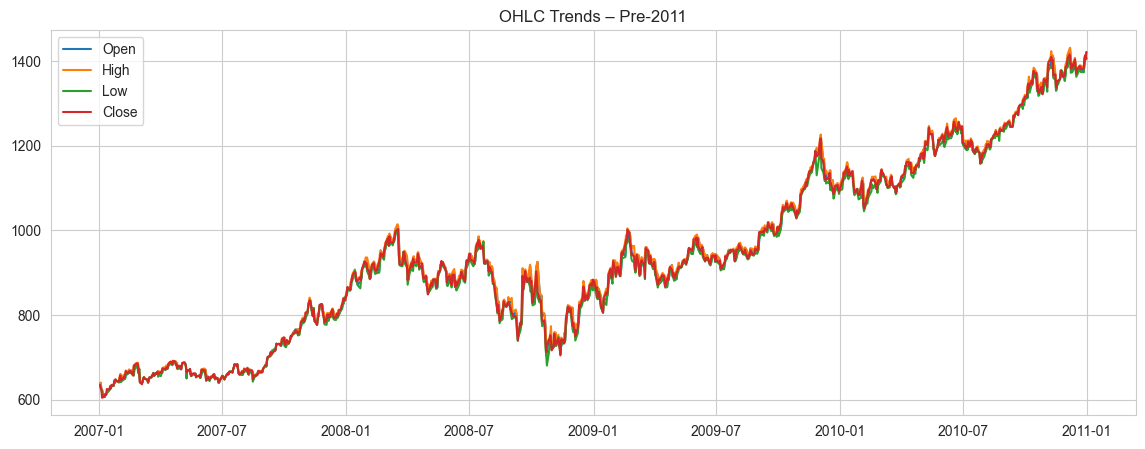

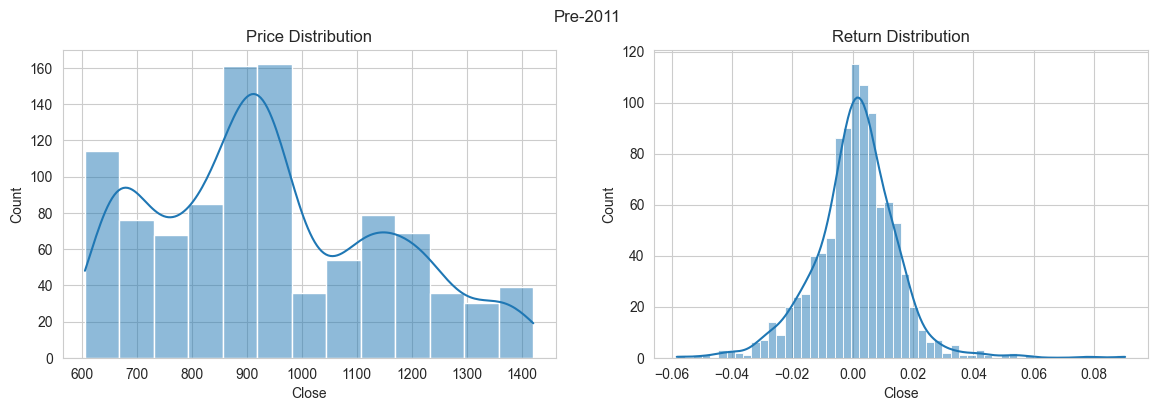

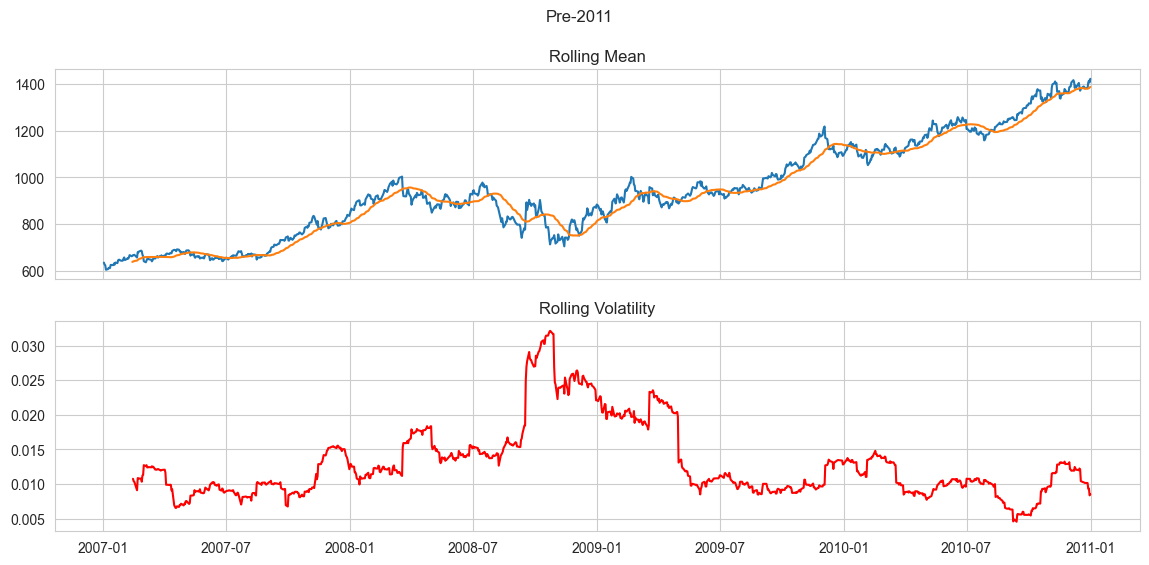

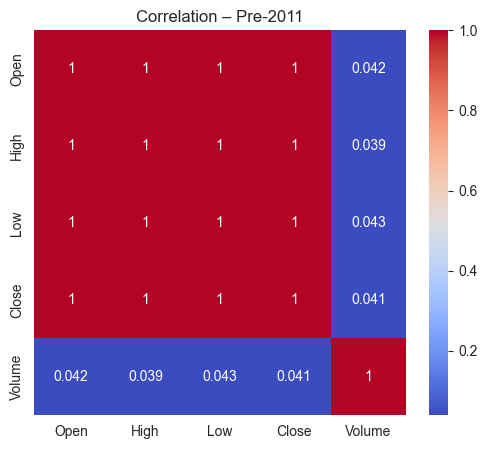


===== STATISTICAL ANALYSIS: Pre-2011 =====
Mean: 942.3389490919614
Std: 207.78494343256597
Skew: 0.40220783365028867
Kurtosis: -0.6914339400048988
ADF p: 0.9423971853775024
KPSS p: 0.01


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\1012217743.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print("KPSS p:", kpss(s, regression="c")[1])


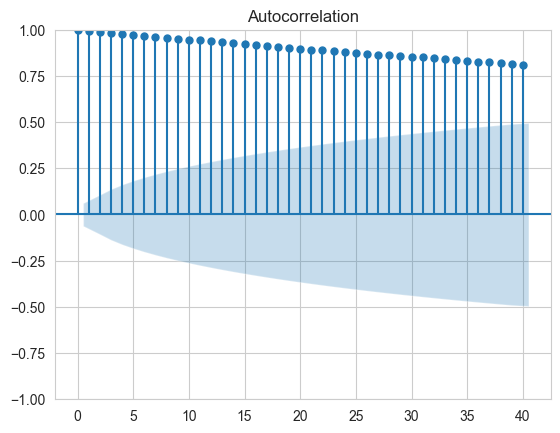

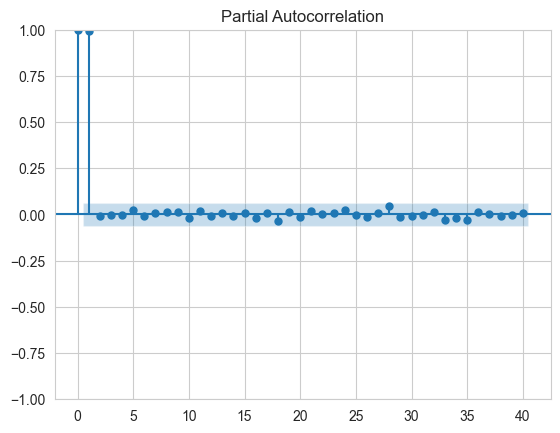

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
ConvLSTM Pre-2011 High | MAE:37.380 RMSE:46.953 R2:0.636
ConvLSTM Pre-2011 Low | MAE:42.032 RMSE:50.678 R2:0.540
XGBoost Pre-2011 High | MAE:99.037 RMSE:126.461 R2:-1.641
XGBoost Pre-2011 Low | MAE:81.112 RMSE:106.052 R2:-1.015


================ 2011–2019 =================


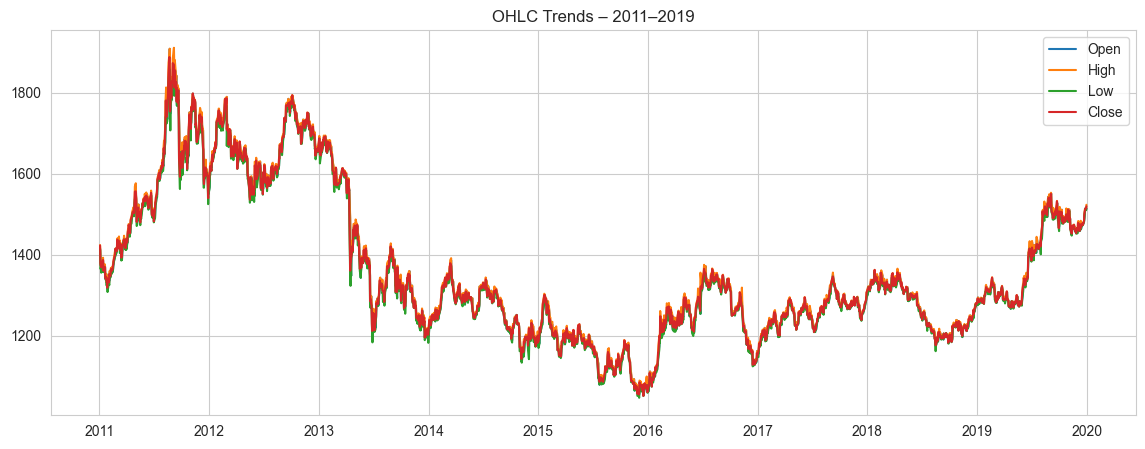

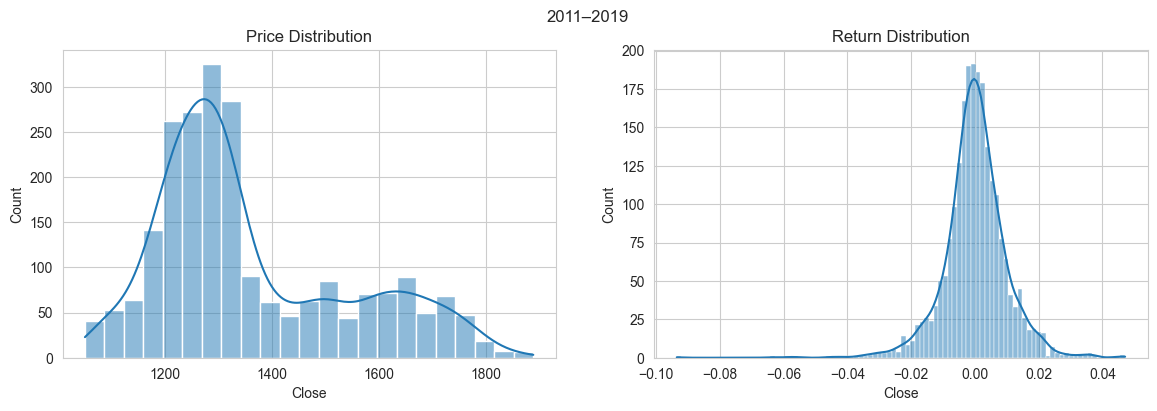

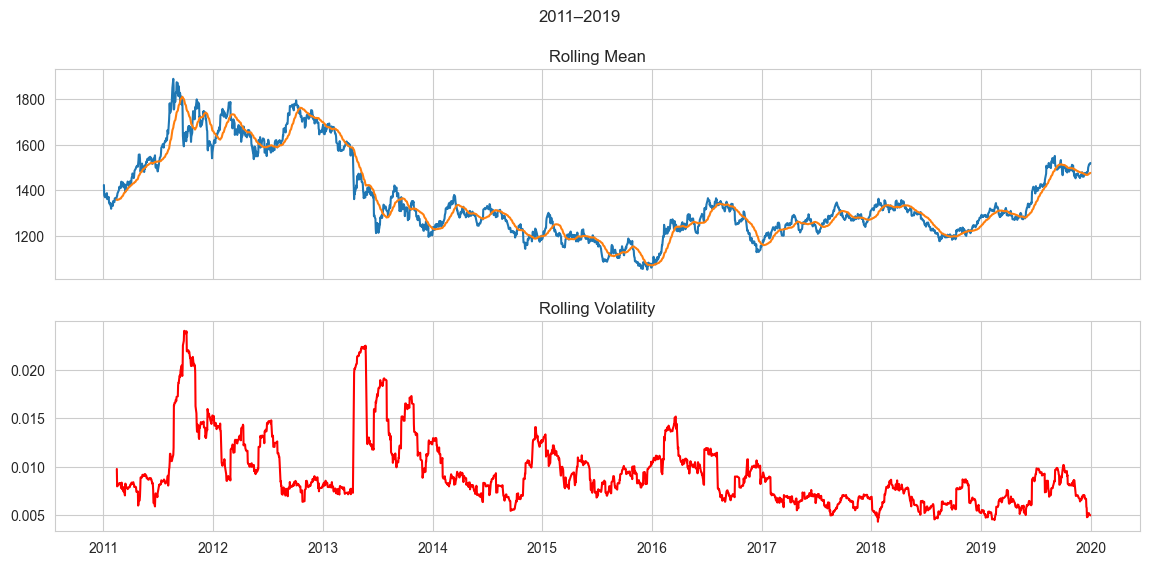

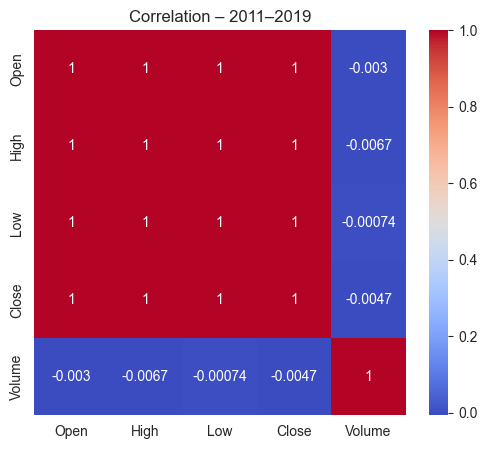


===== STATISTICAL ANALYSIS: 2011–2019 =====
Mean: 1360.176337935976
Std: 181.07976997046384
Skew: 0.8417003845476406
Kurtosis: -0.2766914110108041
ADF p: 0.4534322866983777
KPSS p: 0.01


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\1012217743.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print("KPSS p:", kpss(s, regression="c")[1])


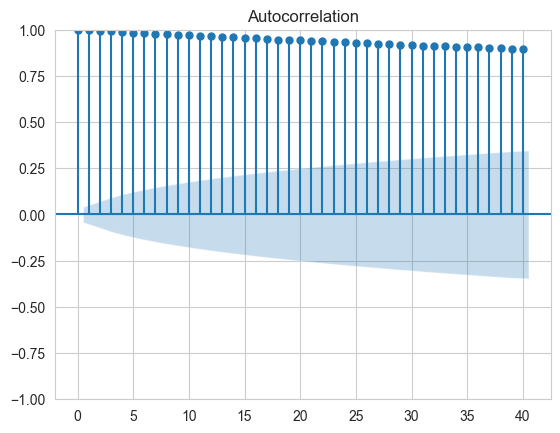

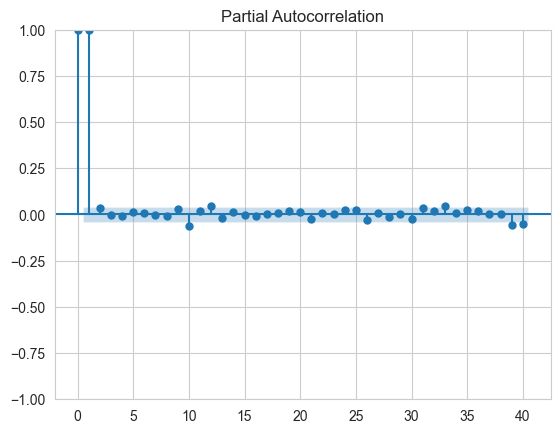

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
ConvLSTM 2011–2019 High | MAE:7.130 RMSE:10.102 R2:0.992
ConvLSTM 2011–2019 Low | MAE:8.520 RMSE:10.631 R2:0.990
XGBoost 2011–2019 High | MAE:7.810 RMSE:10.378 R2:0.991
XGBoost 2011–2019 Low | MAE:7.626 RMSE:9.932 R2:0.992


================ COVID =================


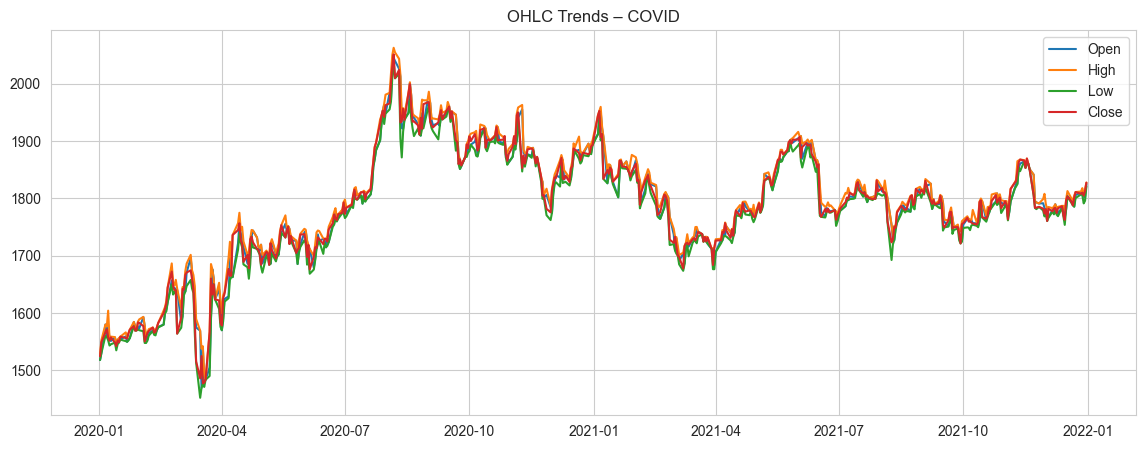

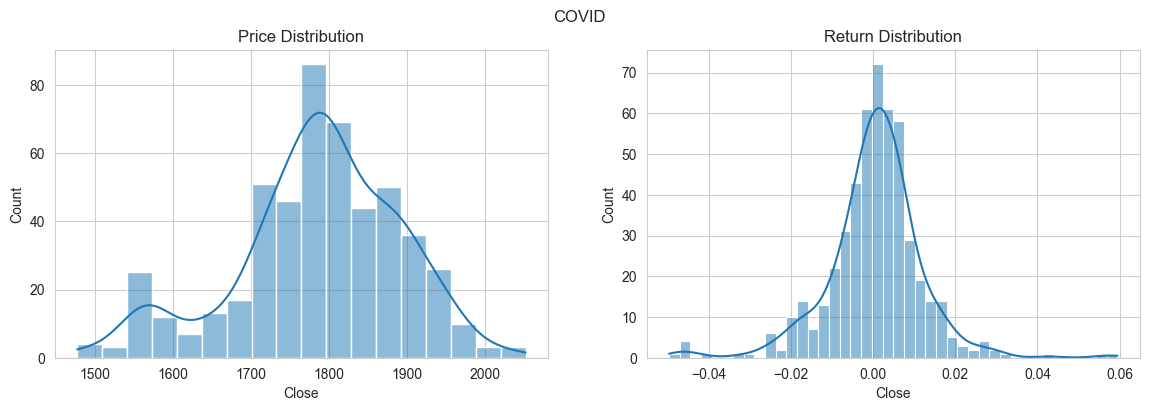

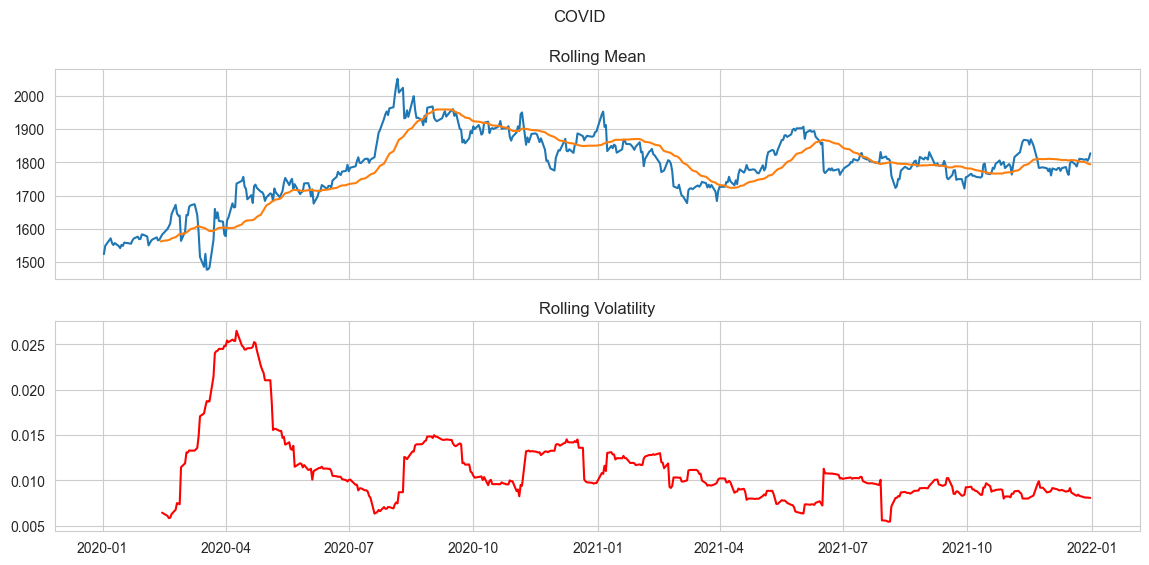

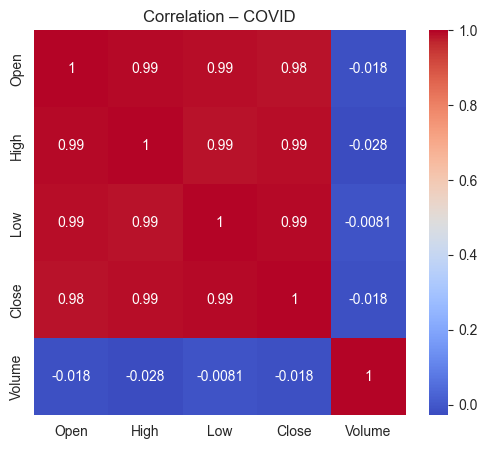


===== STATISTICAL ANALYSIS: COVID =====
Mean: 1785.392275245591
Std: 105.44184249437355
Skew: -0.5287208386794164
Kurtosis: 0.24717785781908974
ADF p: 0.12946788093828587
KPSS p: 0.01


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\1012217743.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print("KPSS p:", kpss(s, regression="c")[1])


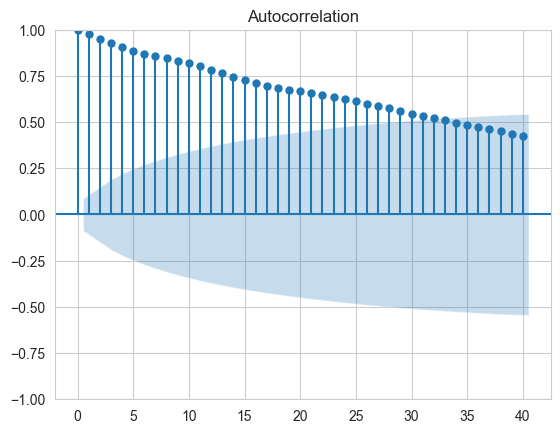

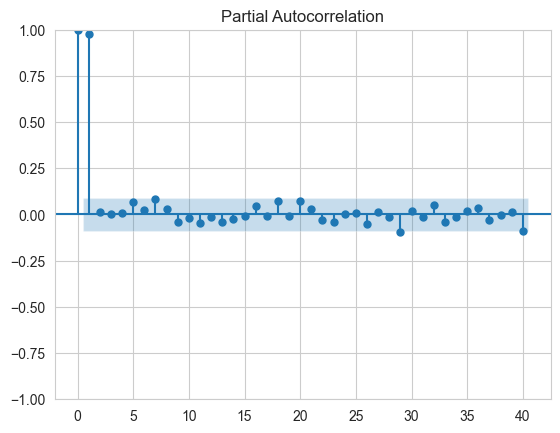

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
ConvLSTM COVID High | MAE:11.193 RMSE:13.786 R2:0.796
ConvLSTM COVID Low | MAE:9.751 RMSE:12.864 R2:0.844
XGBoost COVID High | MAE:10.911 RMSE:13.941 R2:0.792
XGBoost COVID Low | MAE:9.857 RMSE:12.989 R2:0.841


================ 2022+ =================


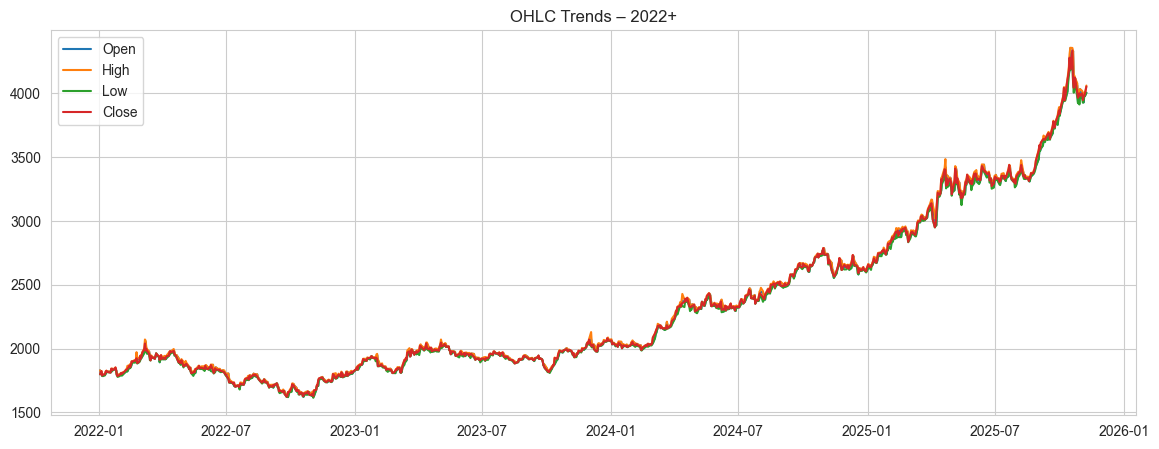

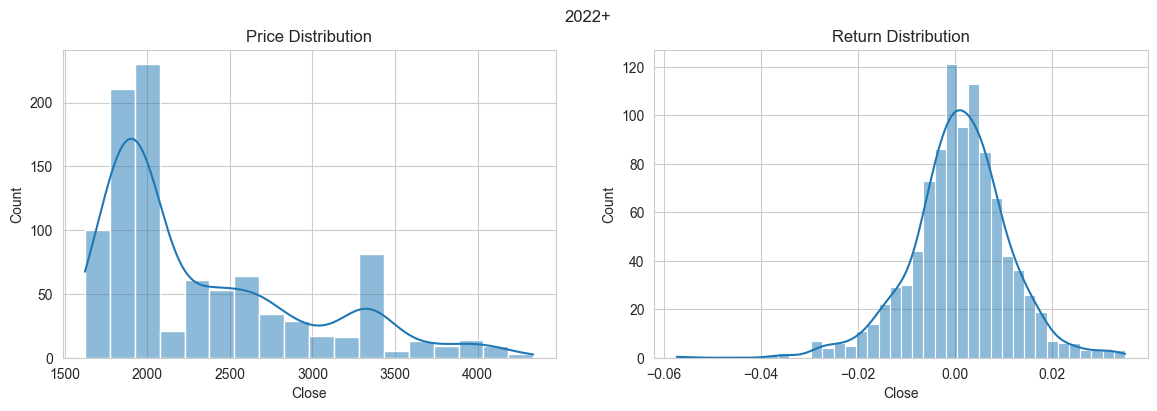

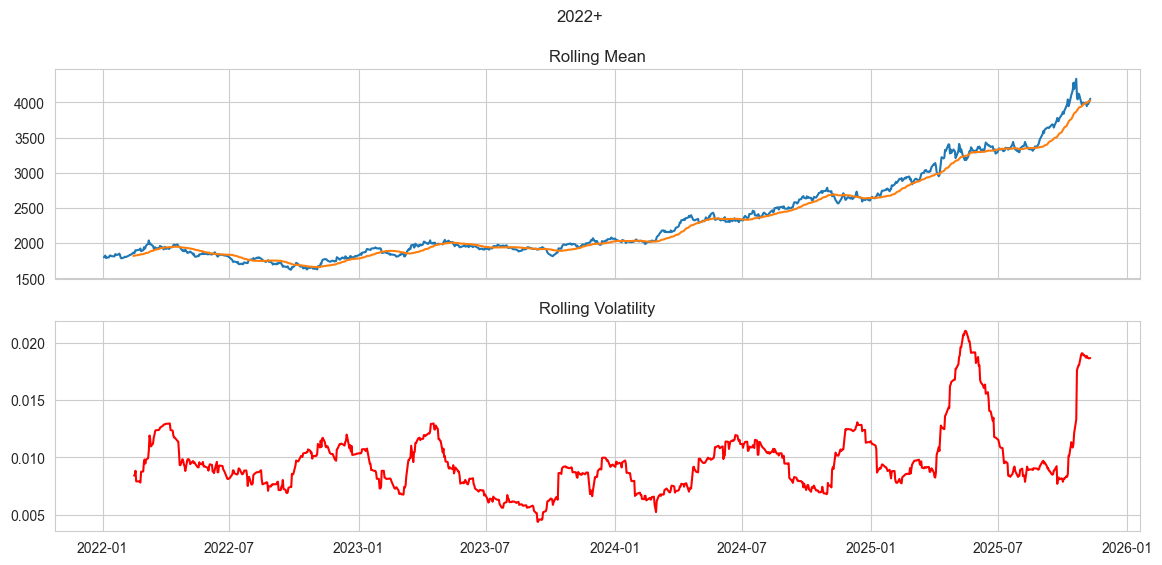

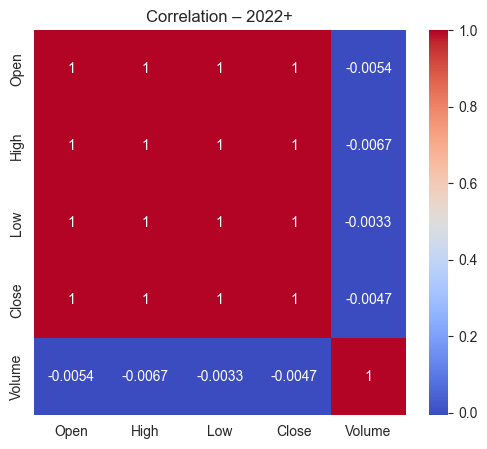


===== STATISTICAL ANALYSIS: 2022+ =====
Mean: 2329.980202838072
Std: 617.2911390005765
Skew: 1.1280649500251863
Kurtosis: 0.30033206994506
ADF p: 0.9988425157514258
KPSS p: 0.01


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\1012217743.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print("KPSS p:", kpss(s, regression="c")[1])


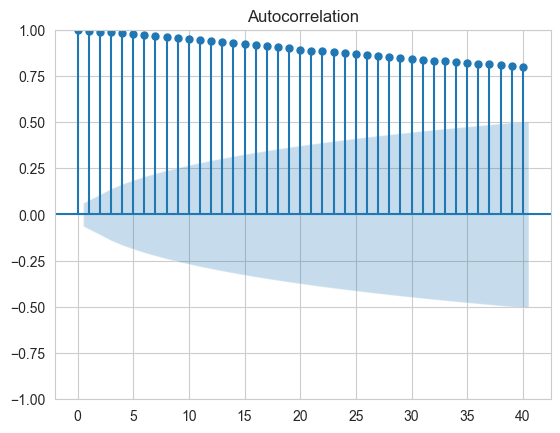

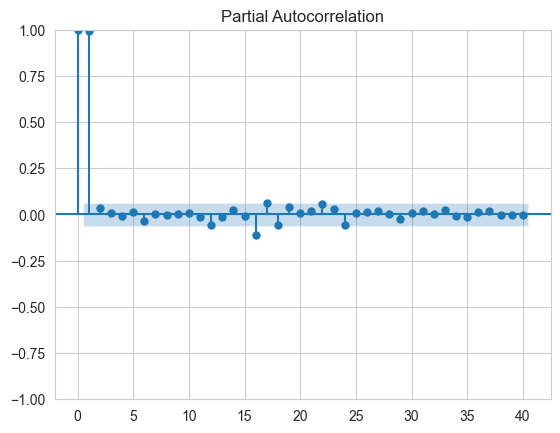

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/stepWARNING:tensorflow:6 out of the last 19 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001EFCB64F250> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
ConvLSTM 2022+ High | MAE:143.782 RMSE:224.708 R2:0.436
ConvLSTM 2022+ Low | MAE:174.060 RMSE:250.408 R2:0.230
XGBoost 2022+ High | MAE:216.760 RMSE:328.543 R2:-0.205
XGBoost 2022+ Low | MAE:209.009

In [13]:
results = {}

for df_r, name in zip(datasets, names):
    print(f"\n\n================ {name} =================")
    plot_price_trends(df_r, name)
    plot_distribution(df_r, name)
    plot_rolling_stats(df_r, name)
    plot_corr_heatmap(df_r, name)
    analyze_timeseries(df_r, name)

    results[name] = {
        "ConvLSTM": run_convlstm(df_r, name),
        "XGBoost": run_xgboost(df_r, name)
    }

In [15]:
def get_stats(df, target="Close"):
    s = df[target].dropna()

    stats = {}

    # Basic statistics
    stats["Mean"] = s.mean()
    stats["Std"]  = s.std()
    stats["CV"]   = s.std() / s.mean()

    # Distribution shape
    stats["Skewness"] = skew(s)
    stats["Kurtosis"] = kurtosis(s, fisher=True)

    # Normality
    stats["JB_pvalue"] = jarque_bera(s)[1]

    # Stationarity
    stats["ADF_pvalue"] = adfuller(s)[1]

    try:
        stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
    except:
        stats["KPSS_pvalue"] = np.nan

    return stats


In [16]:
results = pd.DataFrame({
    "FULL_DATA": get_stats(df),
    "DF1": get_stats(df1),
    "DF2": get_stats(df2),
    "DF3": get_stats(df3),
    "DF4": get_stats(df4)
})

results = results.round(4)
results


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_26192\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values av

,FULL_DATA,DF1,DF2,DF3,DF4
Mean,1514.8330,942.3389,1360.1763,1785.3923,2329.9802
Std,573.2113,207.7849,181.0798,105.4418,617.2911
CV,0.3784,0.2205,0.1331,0.0591,0.2649
Skewness,1.5756,0.4022,0.8417,-0.5287,1.1281
Kurtosis,3.6569,-0.6914,-0.2767,0.2472,0.3003
JB_pvalue,0.0000,0.0000,0.0000,0.0000,0.0000
ADF_pvalue,1.0000,0.9424,0.4534,0.1295,0.9988
KPSS_pvalue,0.0100,0.0100,0.0100,0.0100,0.0100


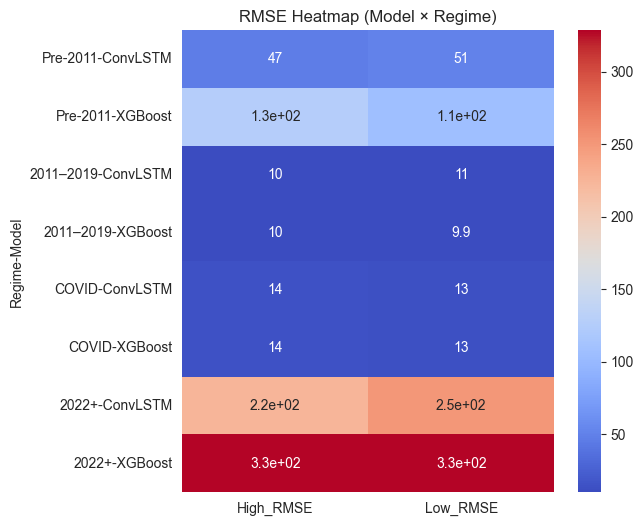

In [14]:
rows = []
for reg, models in results.items():
    for m, out in models.items():
        rows.append([reg,m,out[0][1],out[1][1]])

df_heat = pd.DataFrame(rows,
                       columns=["Regime","Model","High_RMSE","Low_RMSE"]
                      ).set_index(["Regime","Model"])

plt.figure(figsize=(6,6))
sns.heatmap(df_heat, annot=True, cmap="coolwarm")
plt.title("RMSE Heatmap (Model × Regime)")
plt.show()